# 🤟 BISINDO — Training CNN dari Scratch

**Proyek:** Klasifikasi Isyarat Tangan BISINDO (A–Z)  
**Model:** CNN Custom 5 Blok (dibangun dari scratch)  
**Framework:** TensorFlow / Keras  
**Input Size:** 224 × 224 px  

> ✅ **Memenuhi aturan UAS poin 6** — Model dibangun dari scratch menggunakan `Sequential` + `Conv2D` sendiri, **bukan** menggunakan model AI yang sudah jadi (bukan YOLO, bukan pretrained weights).

---
### Struktur Notebook
1. Instalasi & Import Library
2. Konfigurasi Path & Hyperparameter
3. Cek Dataset
4. Augmentasi & Data Generator
5. Arsitektur Model CNN
6. Compile & Summary Model
7. Callbacks
8. Training
9. Evaluasi di Test Set
10. Visualisasi Grafik Akurasi & Loss
11. Confusion Matrix

## 1. 📦 Instalasi & Import Library

In [1]:
# Jalankan sekali jika belum install
# !pip install tensorflow scikit-learn matplotlib seaborn

In [2]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow version : {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU tersedia       : {gpus}")

TensorFlow version : 2.10.0
GPU tersedia       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. ⚙️ Konfigurasi Path & Hyperparameter

In [3]:
# ── Path ──────────────────────────────────────────────────────
BASE_DIR    = Path(".").resolve()          # folder bisindo/
DATASET_DIR = BASE_DIR / "dataset"
TRAIN_DIR   = DATASET_DIR / "train"
VALID_DIR   = DATASET_DIR / "valid"
TEST_DIR    = DATASET_DIR / "test"

# Output model langsung ke folder frontend
MODEL_PATH  = BASE_DIR / "frontend" / "model_bisindo_cnn.h5"

# ── Hyperparameter ────────────────────────────────────────────
IMG_SIZE      = 224    # 224×224 px — lebih detail dari versi lama (128)
BATCH_SIZE    = 16     # RTX 3050 kuat untuk batch 32 di 224×224
EPOCHS        = 60     # EarlyStopping akan berhenti lebih awal jika konvergen
LEARNING_RATE = 1e-3

print(f"Base Dir   : {BASE_DIR}")
print(f"Model akan disimpan ke: {MODEL_PATH}")
print(f"IMG_SIZE   : {IMG_SIZE}")
print(f"BATCH_SIZE : {BATCH_SIZE}")
print(f"EPOCHS     : {EPOCHS}")

Base Dir   : C:\Users\Taufik Nur Rohman\Downloads\arsip kuliah\sem 5\kecerdasan buatan\bisindo
Model akan disimpan ke: C:\Users\Taufik Nur Rohman\Downloads\arsip kuliah\sem 5\kecerdasan buatan\bisindo\frontend\model_bisindo_cnn.h5
IMG_SIZE   : 224
BATCH_SIZE : 16
EPOCHS     : 60


## 3. 🗂️ Cek Dataset

In [4]:
for split, path in [("train", TRAIN_DIR), ("valid", VALID_DIR), ("test", TEST_DIR)]:
    if not path.exists():
        raise FileNotFoundError(
            f"Folder '{split}' tidak ditemukan: {path}\n"
            "Pastikan struktur dataset:\n"
            "  dataset/train/<kelas>/\n"
            "  dataset/valid/<kelas>/\n"
            "  dataset/test/<kelas>/"
        )
    n_images = sum(len(files) for _, _, files in os.walk(path))
    n_classes = len(list(path.iterdir()))
    print(f"✅ {split:5s} — {n_classes} kelas, {n_images} gambar")

✅ train — 26 kelas, 44591 gambar
✅ valid — 26 kelas, 5825 gambar
✅ test  — 26 kelas, 896 gambar


## 4. 🔄 Augmentasi & Data Generator

In [5]:
# ── Augmentasi pada TRAIN dengan Preprocessing resmi MobileNetV2 ──
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# ── Validasi & Test: menggunakan preprocess_input tanpa augmentasi ──
val_datagen  = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)
valid_generator = val_datagen.flow_from_directory(
    str(VALID_DIR),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
test_generator = test_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

NUM_CLASSES  = len(train_generator.class_indices)
CLASS_NAMES  = list(train_generator.class_indices.keys())

print(f"Jumlah kelas : {NUM_CLASSES}")
print(f"Kelas        : {CLASS_NAMES}")
print(f"Data train   : {train_generator.samples}")
print(f"Data valid   : {valid_generator.samples}")
print(f"Data test    : {test_generator.samples}")

Found 44591 images belonging to 26 classes.
Found 5825 images belonging to 26 classes.
Found 896 images belonging to 26 classes.
Jumlah kelas : 26
Kelas        : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Data train   : 44591
Data valid   : 5825
Data test    : 896


### Preview Contoh Gambar Training (dengan Augmentasi)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8745098..-0.0745098].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.99215686].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.827451].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.92156863].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.79607844].
Clipping input data to the val

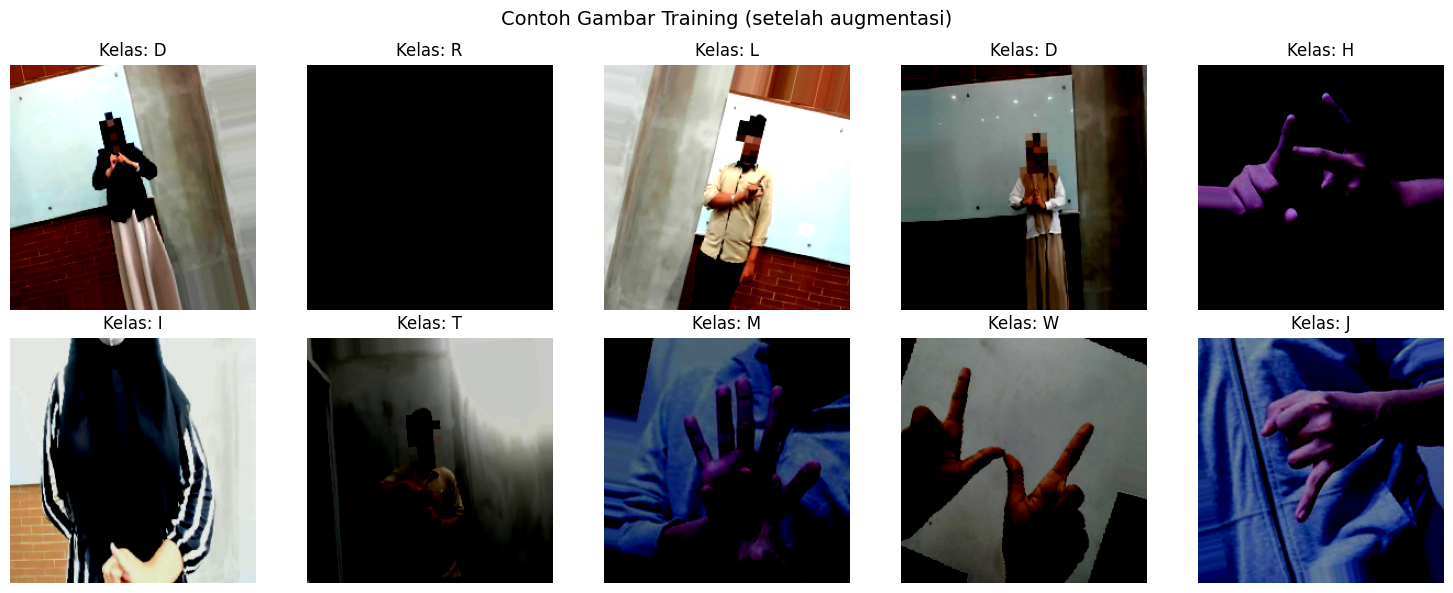

In [6]:
sample_batch, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Contoh Gambar Training (setelah augmentasi)", fontsize=14)
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_batch[i])
    label_idx = np.argmax(sample_labels[i])
    ax.set_title(f"Kelas: {CLASS_NAMES[label_idx]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. 🧠 Arsitektur Model CNN Custom

Model dibangun **dari scratch** menggunakan `Sequential` Keras.  
Tidak menggunakan pretrained weights — ✅ sesuai aturan UAS poin 6.

| Blok | Filter | Keterangan |
|------|--------|------------|
| Blok 1 | 32 | 2× Conv2D + BN + MaxPool + Dropout |
| Blok 2 | 64 | 2× Conv2D + BN + MaxPool + Dropout |
| Blok 3 | 128 | 2× Conv2D + BN + MaxPool + Dropout |
| Blok 4 | 256 | 2× Conv2D + BN + MaxPool + Dropout |
| Blok 5 | 512 | 1× Conv2D + BN + MaxPool + Dropout |
| Head | — | GlobalAvgPool → Dense(512) → Softmax |

In [7]:
def build_transfer_learning_model(num_classes, img_size):
    # 1. Base Model MobileNetV2 Pretrained ImageNet
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(img_size, img_size, 3)
    )

    # Bekukan layer awal, buka 30 layer terakhir untuk fine-tuning
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # 2. Custom Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    predictions = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=predictions, name="BISINDO_MobileNetV2")
    return model

model = build_transfer_learning_model(NUM_CLASSES, IMG_SIZE)
print("✅ Arsitektur MobileNetV2 Transfer Learning berhasil dibuat!")

✅ Arsitektur MobileNetV2 Transfer Learning berhasil dibuat!


## 6. 🔧 Compile & Summary Model

In [8]:
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "BISINDO_MobileNetV2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 Conv1 (Conv2D)                 (None, 112, 112, 32  864         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 bn_Conv1 (BatchNormalization)  (None, 112, 112, 32  128         ['Conv1[0][0]']                  
                                )                                               

## 7. 📋 Callbacks

In [9]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

callbacks = [
    # Simpan bobot terbaik berdasarkan val_accuracy
    ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    # Kurangi LR jika val_accuracy stagnan 4 epoch
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    # Hentikan training jika val_loss tidak membaik 10 epoch
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
]

print("✅ Callbacks siap:")
print("   - ModelCheckpoint  → simpan model terbaik ke:", MODEL_PATH)
print("   - ReduceLROnPlateau → kurangi LR jika stagnan 4 epoch")
print("   - EarlyStopping     → berhenti jika val_loss tidak membaik 10 epoch")

✅ Callbacks siap:
   - ModelCheckpoint  → simpan model terbaik ke: C:\Users\Taufik Nur Rohman\Downloads\arsip kuliah\sem 5\kecerdasan buatan\bisindo\frontend\model_bisindo_cnn.h5
   - ReduceLROnPlateau → kurangi LR jika stagnan 4 epoch
   - EarlyStopping     → berhenti jika val_loss tidak membaik 10 epoch


## 8. 🚀 Training

In [10]:
print("=" * 60)
print("  MEMULAI TRAINING CNN BISINDO")
print(f"  Input size  : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Batch size  : {BATCH_SIZE}")
print(f"  Epochs maks : {EPOCHS}")
print(f"  Jumlah kelas: {NUM_CLASSES}")
print("=" * 60)

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=valid_generator,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Training selesai!")
print(f"   Model terbaik tersimpan di: {MODEL_PATH}")

  MEMULAI TRAINING CNN BISINDO
  Input size  : 224×224
  Batch size  : 16
  Epochs maks : 60
  Jumlah kelas: 26
Epoch 1/60
2787/2787 [==============================] - ETA: 0s - loss: 0.9866 - accuracy: 0.7010
Epoch 1: val_accuracy improved from -inf to 0.70575, saving model to C:\Users\Taufik Nur Rohman\Downloads\arsip kuliah\sem 5\kecerdasan buatan\bisindo\frontend\model_bisindo_cnn.h5
2787/2787 [==============================] - 622s 222ms/step - loss: 0.9866 - accuracy: 0.7010 - val_loss: 1.1689 - val_accuracy: 0.7058 - lr: 0.0010
Epoch 2/60
2787/2787 [==============================] - ETA: 0s - loss: 0.5795 - accuracy: 0.8143
Epoch 2: val_accuracy improved from 0.70575 to 0.78266, saving model to C:\Users\Taufik Nur Rohman\Downloads\arsip kuliah\sem 5\kecerdasan buatan\bisindo\frontend\model_bisindo_cnn.h5
2787/2787 [==============================] - 653s 234ms/step - loss: 0.5795 - accuracy: 0.8143 - val_loss: 0.8685 - val_accuracy: 0.7827 - lr: 0.0010
Epoch 3/60
2787/2787 [=====

## 9. 🧪 Evaluasi di Test Set

In [16]:
print("Mengevaluasi model pada test set...")
test_loss, test_acc = model.evaluate(test_generator, verbose=1)

print(f"\n{'='*40}")
print(f"  Test Accuracy : {test_acc * 100:.2f}%")
print(f"  Test Loss     : {test_loss:.4f}")
print(f"{'='*40}")

Mengevaluasi model pada test set...
56/56 [==============================] - 3s 46ms/step - loss: 2.0334e-05 - accuracy: 1.0000

  Test Accuracy : 100.00%
  Test Loss     : 0.0000


## 10. 📈 Visualisasi Grafik Akurasi & Loss

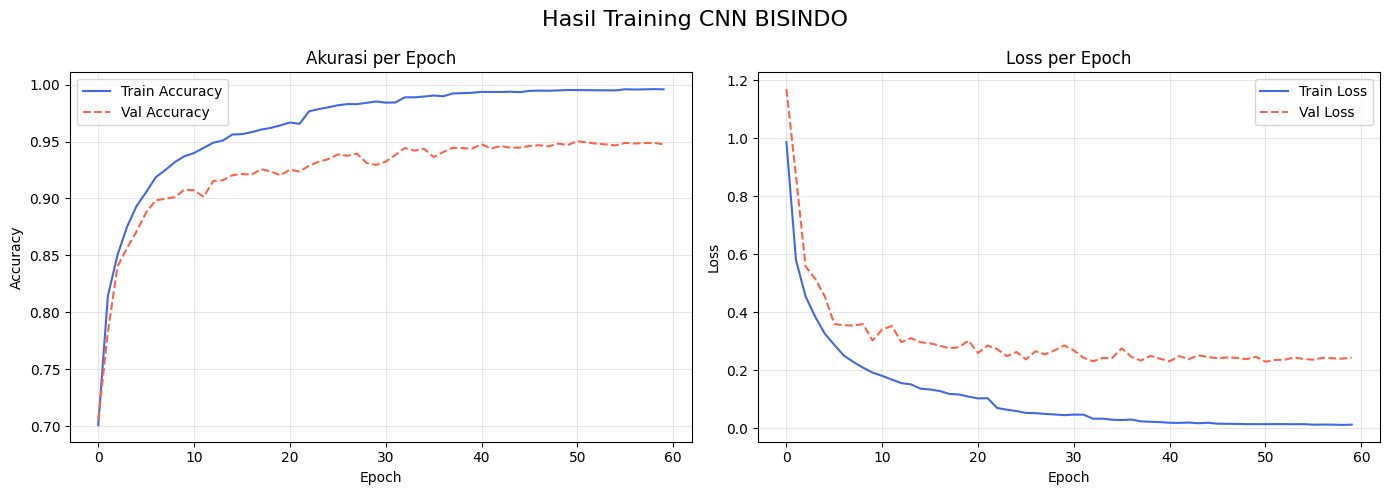

Grafik disimpan ke training_history.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Hasil Training CNN BISINDO", fontsize=16)

# ── Akurasi ──
axes[0].plot(history.history['accuracy'],     label='Train Accuracy',  color='royalblue')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',    color='tomato', linestyle='--')
axes[0].set_title('Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Loss ──
axes[1].plot(history.history['loss'],     label='Train Loss',  color='royalblue')
axes[1].plot(history.history['val_loss'], label='Val Loss',    color='tomato', linestyle='--')
axes[1].set_title('Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(BASE_DIR / "training_history.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke training_history.png")

## 11. 🗺️ Confusion Matrix & Classification Report

> Bagian ini menghasilkan **Matriks Pengujian** yang diminta di poin 9 UAS.

In [18]:
# Reset generator agar prediksi dari awal
test_generator.reset()

predictions = model.predict(test_generator, verbose=1)
y_pred      = np.argmax(predictions, axis=1)
y_true      = test_generator.classes

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

56/56 [==============================] - 3s 48ms/step

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        52
           B       1.00      1.00      1.00         9
           C       1.00      1.00      1.00        20
           D       1.00      1.00      1.00        31
           E       1.00      1.00      1.00        37
           F       1.00      1.00      1.00        26
           G       1.00      1.00      1.00        48
           H       1.00      1.00      1.00        29
           I       1.00      1.00      1.00        36
           J       1.00      1.00      1.00        31
           K       1.00      1.00      1.00        41
           L       1.00      1.00      1.00        33
           M       1.00      1.00      1.00        44
           N       1.00      1.00      1.00        37
           O       1.00      1.00      1.00        23
           P       1.00      1.00      1.00       

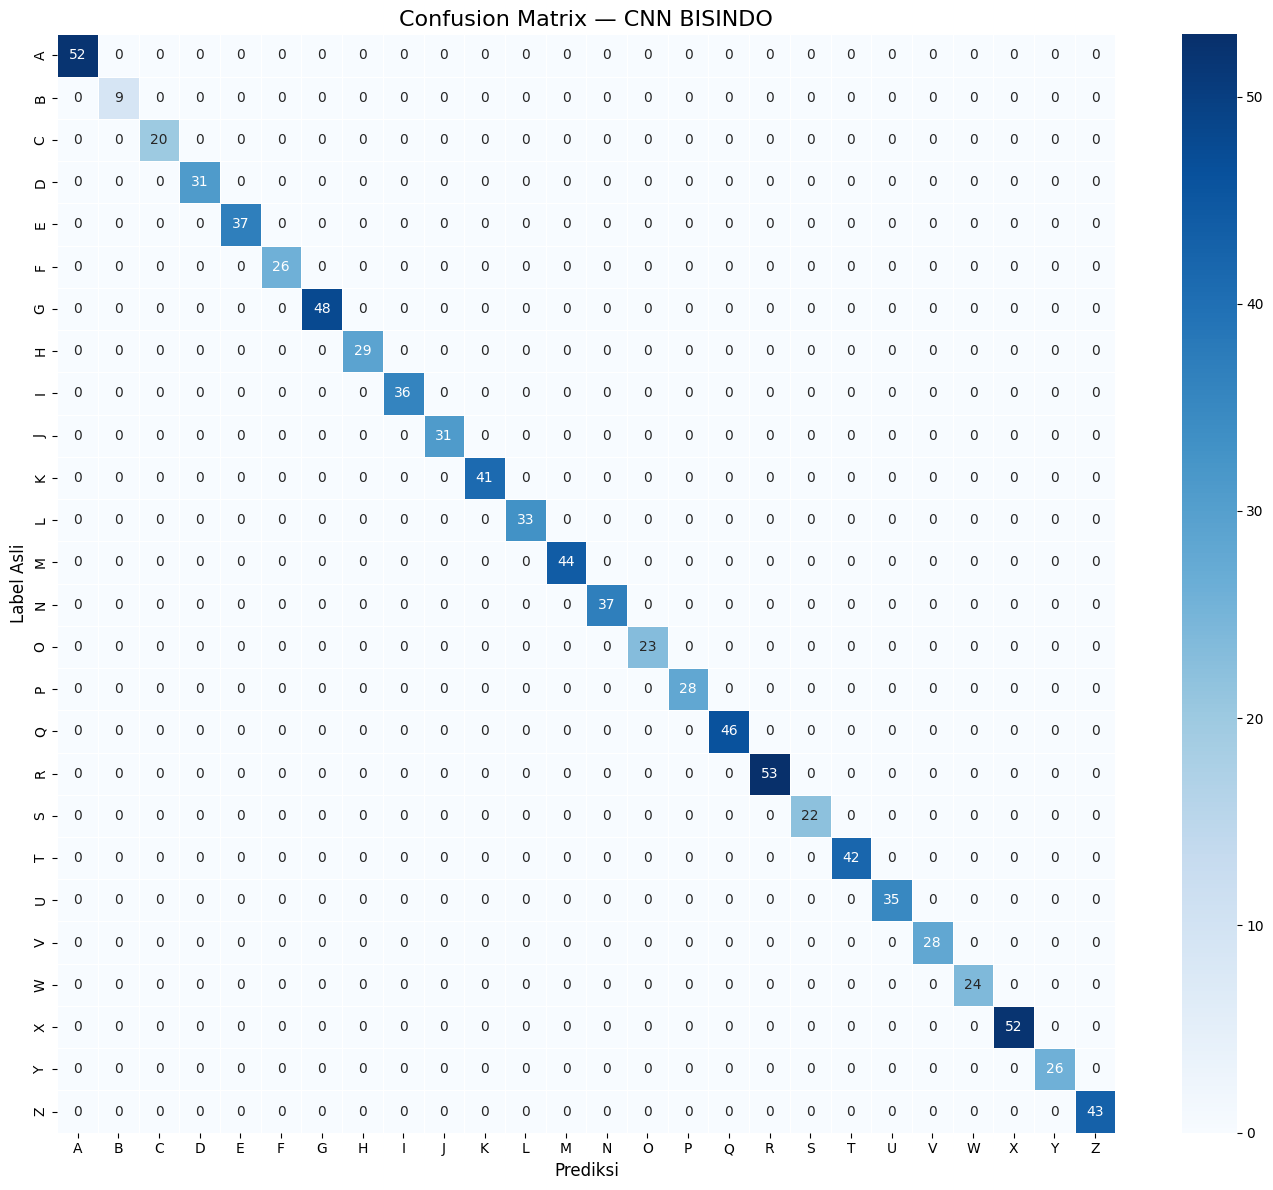

Confusion matrix disimpan ke confusion_matrix.png


In [19]:
# ── Plot Confusion Matrix ──
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.5, ax=ax
)
ax.set_title('Confusion Matrix — CNN BISINDO', fontsize=16)
ax.set_xlabel('Prediksi', fontsize=12)
ax.set_ylabel('Label Asli', fontsize=12)
plt.tight_layout()
plt.savefig(str(BASE_DIR / "confusion_matrix.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix disimpan ke confusion_matrix.png")

In [ ]:
# ── Identifikasi huruf yang sering tertukar ──
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

print("=== HURUF YANG SERING TERTUKAR (> 3 kali) ===")
ditemukan = False
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if cm_no_diag[i, j] > 3:
            print(f"  '{CLASS_NAMES[i]}' salah diprediksi sebagai '{CLASS_NAMES[j]}': {cm_no_diag[i,j]} kali")
            ditemukan = True

if not ditemukan:
    print("  ✅ Model solid — tidak ada salah prediksi dominan!")

=== HURUF YANG SERING TERTUKAR (> 3 kali) ===
  ✅ Model solid — tidak ada salah prediksi dominan!


: 